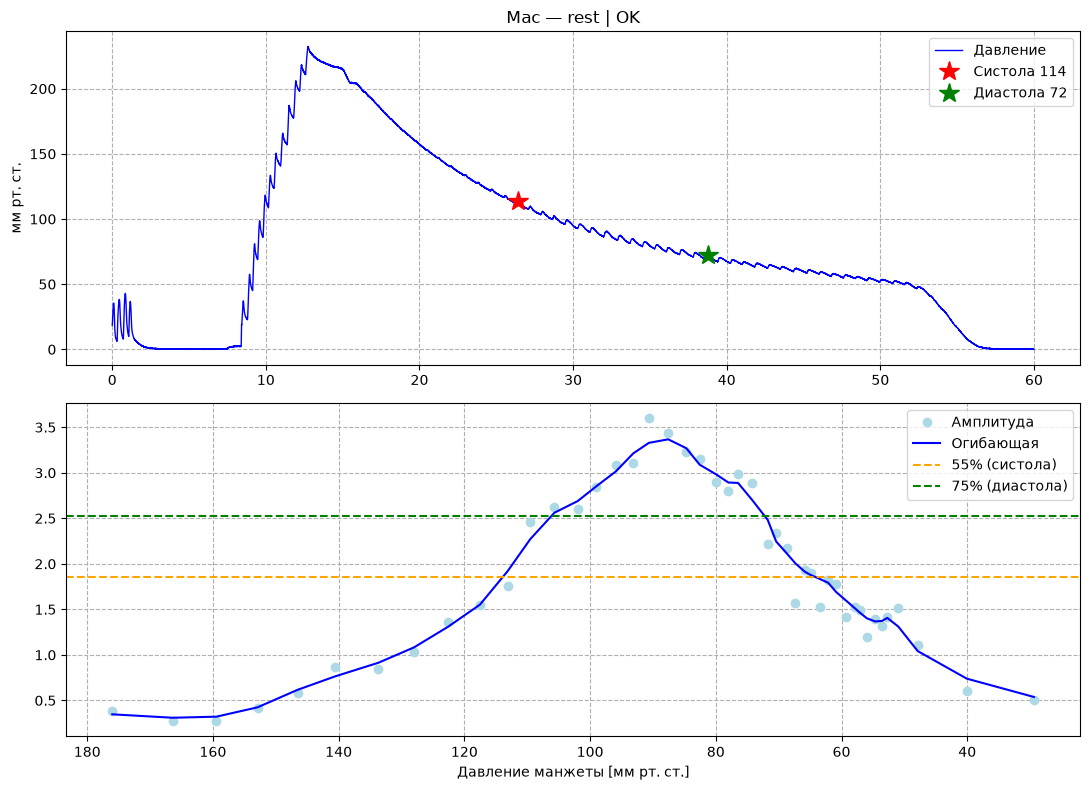

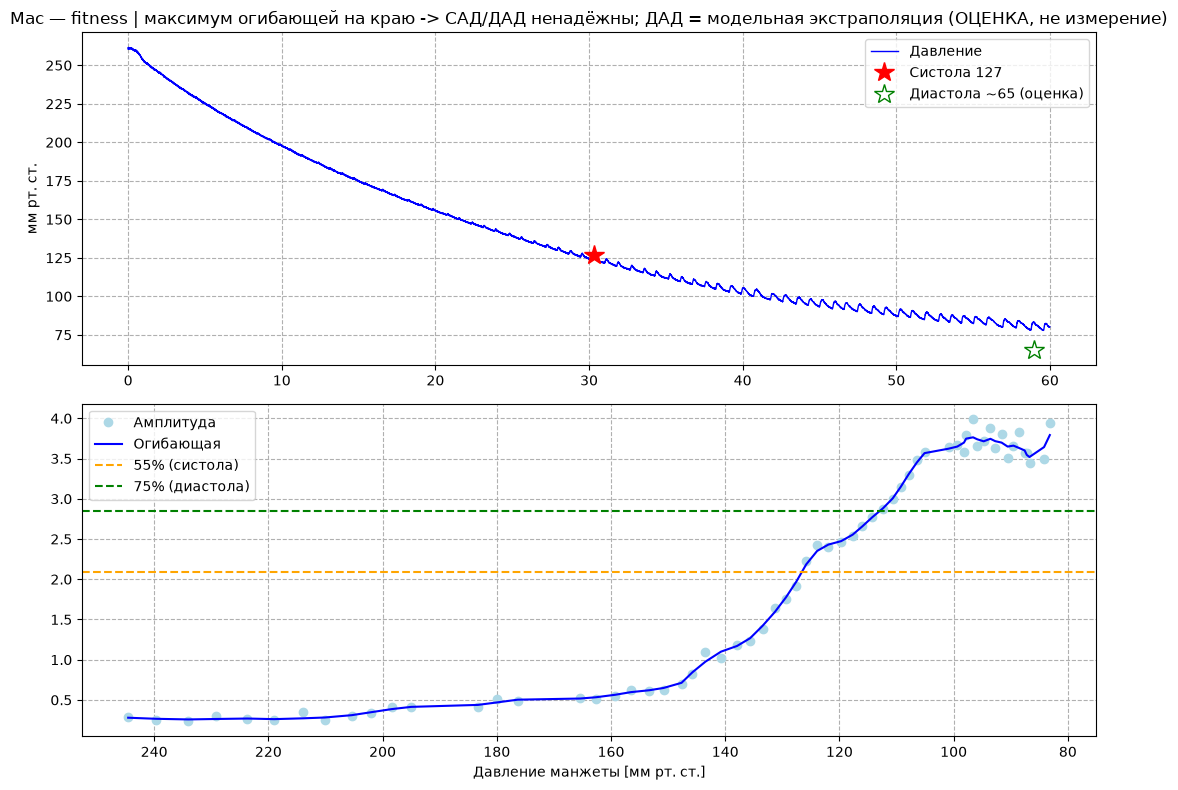

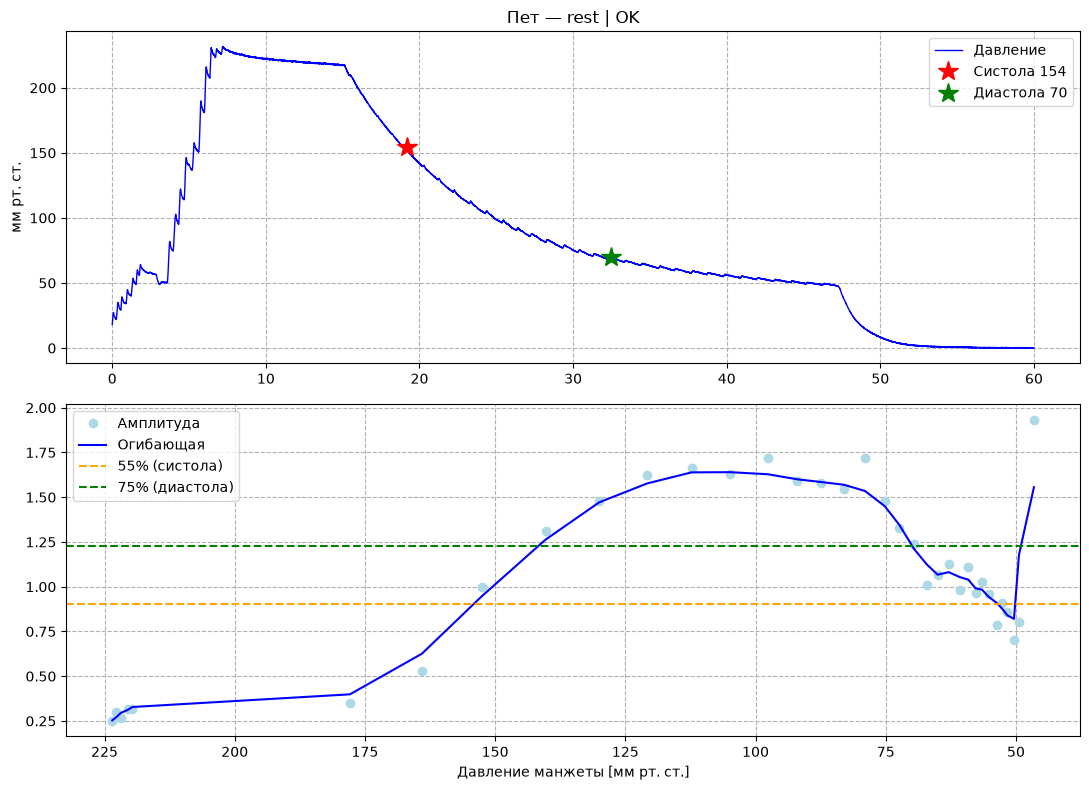

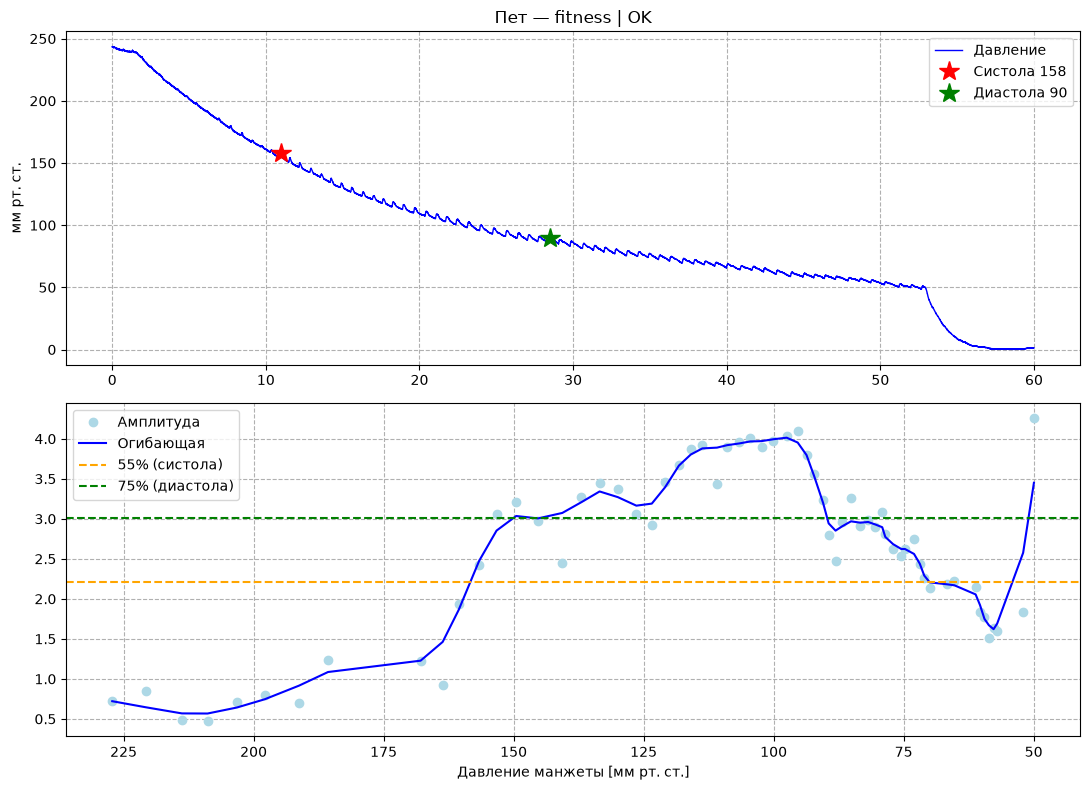

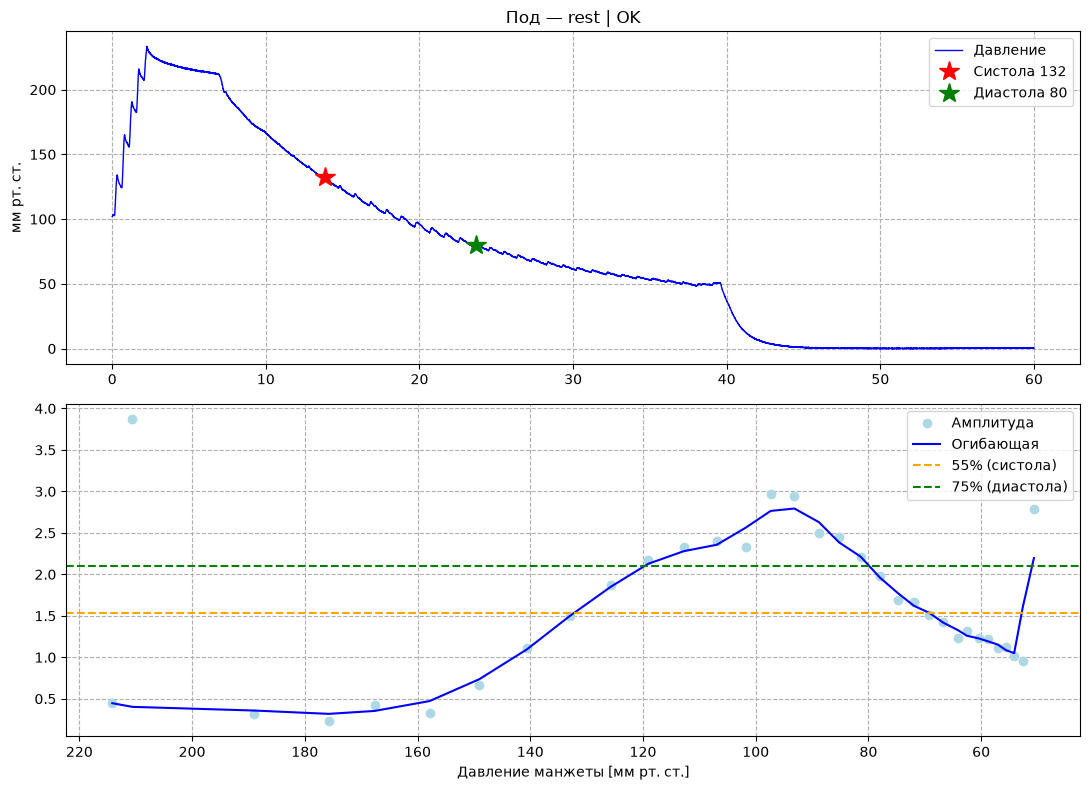

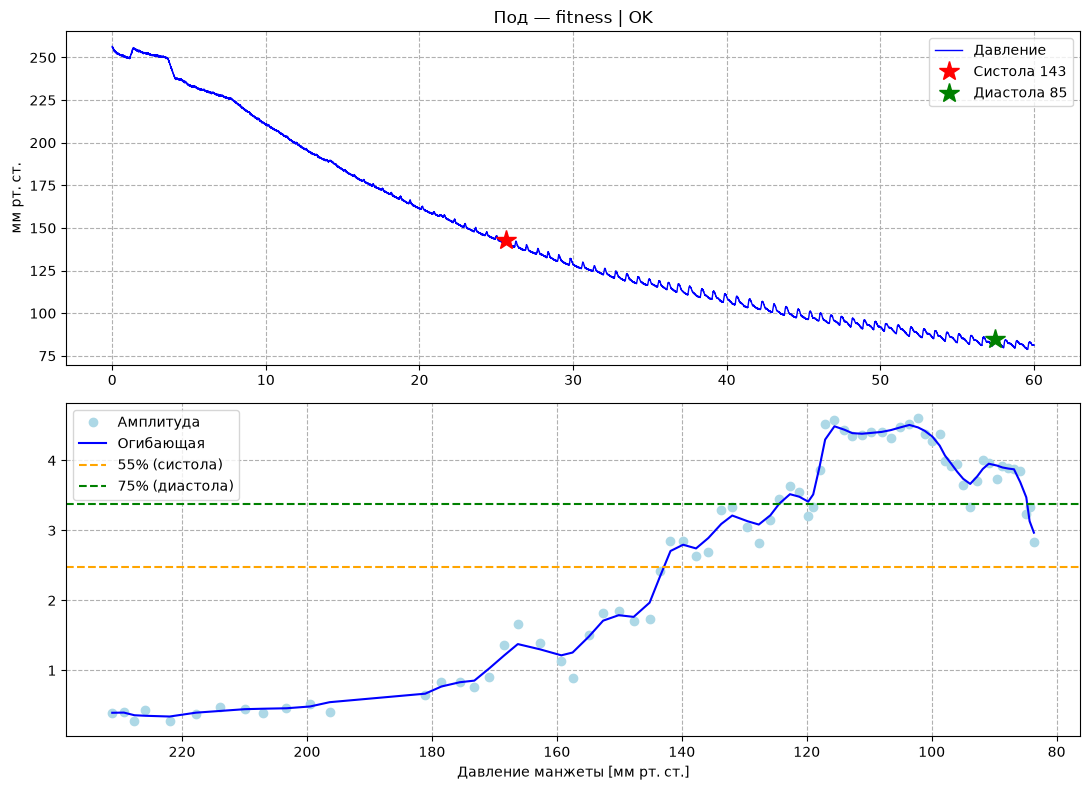


 subject    cond     pulse        sbp       dbp        map  extrap  trunc                                                                                                  warn
    Мас    rest 73.877978 113.932261 72.230697  87.567425   False  False                                                                                                    OK
    Мас fitness 75.084470 126.620066 65.160530  83.157950    True   True максимум огибающей на краю -> САД/ДАД ненадёжны; ДАД = модельная экстраполяция (ОЦЕНКА, не измерение)
    Пет    rest 58.694057 154.167840 69.965176 104.886475   False  False                                                                                                    OK
    Пет fitness 86.070865 158.348612 89.706637  97.501900   False  False                                                                                                    OK
    Под    rest 61.152729 132.191903 79.788525  93.145650   False  False                                                   

In [5]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, find_peaks
from scipy.ndimage import median_filter, uniform_filter1d
from scipy.optimize import curve_fit

DATA_DIR = '.'
FILES = {
    'Мас': {'rest': 'rest_Mas.csv', 'fitness': 'fitness_Mas.csv'},
    'Пет': {'rest': 'rest_Pet.csv', 'fitness': 'fitness_Pet.csv'},
    'Под': {'rest': 'rest_Pod.csv', 'fitness': 'fitness_Pod.csv'},
}
K_SYS, K_DIA = 0.55, 0.75
FS_NEW = 200
ALLOW_MODEL_EXTRAP = True   # оценка ДАД для обрезанных записей (не измерение!)

def load(path):
    txt = open(path, encoding='utf-8', errors='ignore').read()
    nums = np.array([float(x) for x in re.findall(r'-?\d+\.\d{4}', txt)])
    if nums.size >= 4 and nums.size % 2 == 0:
        t, p = nums[0::2], nums[1::2]
    else:
        df = pd.read_csv(path, header=None)
        t, p = df.iloc[:,0].to_numpy(float), df.iloc[:,1].to_numpy(float)
    ok = np.isfinite(t) & np.isfinite(p); t, p = t[ok], p[ok]
    o = np.argsort(t); t, p = t[o], p[o]; t = t - t[0]
    if p.max() < 10: p = 83.66*p - 11.33
    return t, p

def downsample(t, p, fs_new=FS_NEW):
    fs = 1.0/np.median(np.diff(t))
    k = max(1, int(round(fs/fs_new)))
    p = uniform_filter1d(p, size=k, mode='nearest')
    return t[::k], p[::k], fs/k

def envelope(td, pd_, osc, fs):
    peaks,_ = find_peaks(osc, distance=int(0.35*fs), prominence=0.2)
    win = int(0.30*fs)
    tb, pb, amp = [], [], []
    for pk in peaks:
        a, b = max(0,pk-win), min(len(osc),pk+win)
        if pk-a < 5 or b-pk < 5: continue
        base = 0.5*(osc[a:pk].min() + osc[pk:b].min())
        tb.append(td[pk]); pb.append(pd_[pk]); amp.append(osc[pk]-base)
    tb, pb, amp = map(np.array, (tb, pb, amp))
    if len(amp) < 10: return None
    m = (tb > td[0]+1.5) & (tb < td[-1]-0.5)
    rr = np.diff(tb); med = np.median(rr)
    good = np.ones(len(tb), bool)
    good[1:] &= (rr>0.75*med)&(rr<1.25*med)
    good[:-1] &= (rr>0.75*med)&(rr<1.25*med)
    m &= good
    tb, pb, amp = tb[m], pb[m], amp[m]
    sm = uniform_filter1d(median_filter(amp,3,mode='nearest'),3,mode='nearest')
    return tb, pb, amp, sm

def _gauss(p, A, mu, sig): return A*np.exp(-(p-mu)**2/(2*sig**2))

def estimate(pb, sm, k_sys=K_SYS, k_dia=K_DIA, truncated=False):
    n = len(sm); warn = []
    im = int(np.argmax(sm)); amax = sm[im]
    if im >= n-4: warn.append('максимум огибающей на краю -> САД/ДАД ненадёжны')
    def cross(i0,i1,level,rising):
        seg = sm[i0:i1]
        hit = np.where(seg>=level)[0] if rising else np.where(seg<=level)[0]
        if not len(hit): return None
        j = i0+hit[0]
        if j==i0: return pb[j]
        w = (level-sm[j-1])/(sm[j]-sm[j-1]) if sm[j]!=sm[j-1] else 0
        return pb[j-1]+w*(pb[j]-pb[j-1])
    sbp = cross(0, im+1, k_sys*amax, True)
    dbp = cross(im, n, k_dia*amax, False)
    extrap = False
    if dbp is None and truncated and ALLOW_MODEL_EXTRAP and n >= 8:
        # гауссова модель огибающей: экстраполяция спада ниже конца записи
        try:
            A0 = amax; mu0 = pb[im]; sig0 = max(10.0,(pb[0]-pb[-1])/4)
            popt,_ = curve_fit(_gauss, pb, sm, p0=[A0,mu0,sig0], maxfev=8000,
                               bounds=([0, pb[-1]-80, 5],[A0*3, pb[0]+80, 250]))
            A, mu, sig = popt
            cand = mu - sig*np.sqrt(2*np.log(1.0/k_dia))
            if 0 < cand < pb[-1]:
                dbp, extrap = cand, True
                warn.append('ДАД = модельная экстраполяция (ОЦЕНКА, не измерение)')
        except Exception:
            pass
    if dbp is None: warn.append('ДАД не определён (запись обрезана)')
    return dict(sbp=sbp, dbp=dbp, map=pb[im], amax=amax, im=im,
                extrap=extrap, warn='; '.join(warn) or 'OK')

def analyze(path):
    t, p, fs = downsample(*load(path))
    sm_p = uniform_filter1d(p, int(fs*0.5), mode='nearest')
    i0 = int(np.argmax(sm_p))
    below = np.where(sm_p[i0:] < 20)[0]
    i1 = i0+below[0] if len(below) else len(p)-1
    truncated = len(below)==0
    td, pd_ = t[i0:i1+1], p[i0:i1+1]
    sos = butter(3,[0.8,4.0],btype='band',fs=fs,output='sos')
    osc = sosfiltfilt(sos, pd_)
    env = envelope(td, pd_, osc, fs)
    if env is None: return None
    tb, pb, amp, sm = env
    r = estimate(pb, sm, truncated=truncated)
    r.update(t=t, p=p, tb=tb, pb=pb, amp=amp, sm=sm,
             pulse=60/np.median(np.diff(tb)), truncated=truncated)
    return r

def plot_res(name, cond, r):
    fig, ax = plt.subplots(2,1,figsize=(11,8))
    ax[0].plot(r['t'], r['p'], 'b-', lw=1, label='Давление')
    if r['sbp'] is not None:
        i = int(np.argmin(abs(r['pb']-r['sbp'])))
        ax[0].plot(r['tb'][i], r['sbp'], 'r*', ms=15, label=f"Систола {r['sbp']:.0f}")
    if r['dbp'] is not None:
        i = int(np.argmin(abs(r['pb']-r['dbp'])))
        lbl = f"Диастола ~{r['dbp']:.0f} (оценка)" if r['extrap'] else f"Диастола {r['dbp']:.0f}"
        ax[0].plot(r['tb'][i], r['dbp'], 'g*', ms=15,
                   mfc='none' if r['extrap'] else 'g', label=lbl)
    ax[0].set_title(f"{name} — {cond} | {r['warn']}")
    ax[0].set_ylabel('мм рт. ст.'); ax[0].legend(); ax[0].grid(ls='--')
    ax[1].plot(r['pb'], r['amp'], 'o', color='lightblue', label='Амплитуда')
    ax[1].plot(r['pb'], r['sm'], 'b-', label='Огибающая')
    ax[1].axhline(K_SYS*r['amax'], color='orange', ls='--', label=f'{K_SYS:.0%} (систола)')
    ax[1].axhline(K_DIA*r['amax'], color='green', ls='--', label=f'{K_DIA:.0%} (диастола)')
    ax[1].set_xlabel('Давление манжеты [мм рт. ст.]'); ax[1].invert_xaxis()
    ax[1].legend(); ax[1].grid(ls='--')
    plt.tight_layout(); plt.show()

rows = []
for name, f in FILES.items():
    for cond in ('rest','fitness'):
        path = os.path.join(DATA_DIR, f[cond])
        if not os.path.exists(path): print('НЕТ ФАЙЛА:', path); continue
        r = analyze(path)
        if r is None: print(f'{name} {cond}: мало волн'); continue
        rows.append(dict(subject=name, cond=cond, pulse=r['pulse'], sbp=r['sbp'],
                         dbp=r['dbp'], map=r['map'], extrap=r['extrap'],
                         trunc=r['truncated'], warn=r['warn']))
        plot_res(name, cond, r)
df = pd.DataFrame(rows)
print('\n', df.to_string(index=False))